In [28]:
%load_ext autoreload
%autoreload 2

from pathlib import Path
import sys
path = str(Path(Path('File.py').parent.absolute()).parent.absolute())
sys.path.insert(0, path)

path = str(Path(Path('thermo.py').parent.absolute()).parent.absolute())
sys.path.insert(0, path)

# Lucas notebook

import xarray as xa
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib import cm

from tools.cbook import pickle2Obj, interp_z, compute_thetae
from tools.FV3_tools import read_solo_fields

large = 16; med = 12; small = 10
params = {'axes.titlesize': large,
          'legend.fontsize': med,
          'figure.figsize': (8, 4),
          'axes.labelsize': med,
          'axes.titlesize': large,
          'xtick.labelsize': small,
          'ytick.labelsize': small,
          'figure.titlesize': large,
          'axes.titlepad': 6}
plt.rcParams.update(params)


file = '/work/wicker/climate_runs/FV3_Solo/bubble/euler_nocond/3km/QV14/atmos_hifreq.nc'

ds = xa.open_dataset(file,decode_times=False,chunks={'time': 1})

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [29]:
t = 15

xcoord = [28,35]
ycoord = [28,35]

ds_small=ds.isel(time=t,grid_xt=slice(28,35),grid_yt=slice(28,35))

ds_small2 =ds.isel(time=t+1,grid_xt=slice(28,35),grid_yt=slice(28,35))

ds_ref=ds.isel(time=0,grid_xt=0,grid_yt=0)

ds_cross1=ds_small.sel(grid_yt=32) #,grid_xt=slice(50,70)) #farther away
ds_cross2=ds_small2.sel(grid_yt=32) #,grid_xt=slice(50,70)) #farther away


<xarray.DataArray 'delp' ()> Size: 4B
dask.array<_nanmax_skip-aggregate, shape=(), dtype=float32, chunksize=(), chunktype=numpy.ndarray>
Coordinates:
    grid_yt  float32 4B 32.0
    time     float32 4B 960.0
<xarray.DataArray 'delp' ()> Size: 4B
dask.array<_nanmax_skip-aggregate, shape=(), dtype=float32, chunksize=(), chunktype=numpy.ndarray>
Coordinates:
    grid_yt  float32 4B 32.0
    time     float32 4B 960.0


Text(0.5, 1.0, 'W')

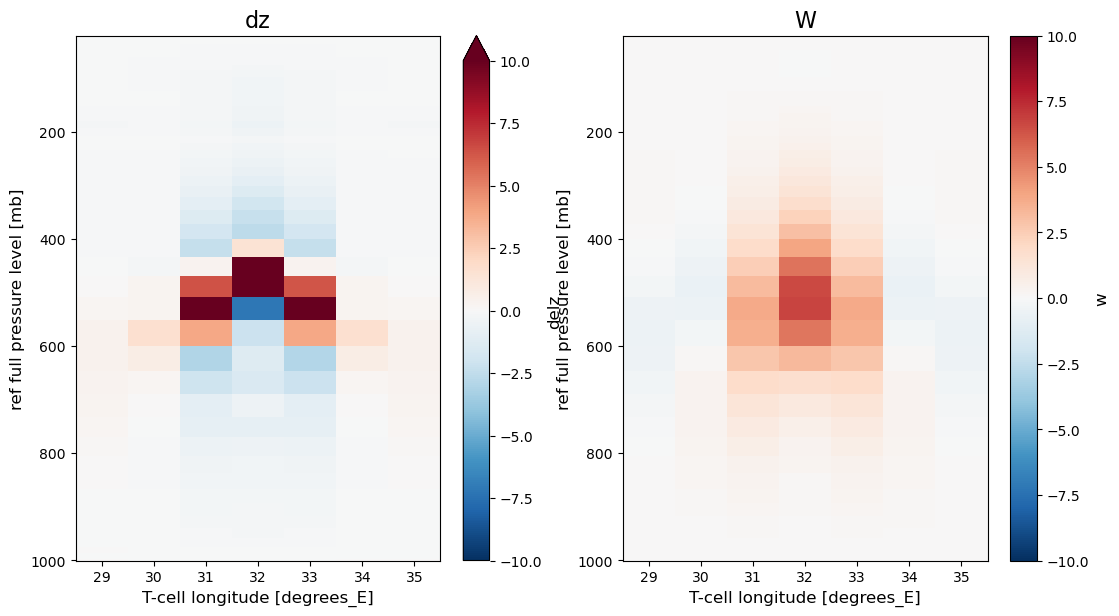

In [32]:
fig = plt.figure(figsize=(20,15))

#nhpres anom
ax = fig.add_subplot(2,3,1)
print(ds_cross.delp.max())
(ds_cross2.delz-ds_cross1.delz).plot(ax=ax,yincrease=False,vmax=10,vmin=-10,cmap=plt.get_cmap('RdBu_r'))
ax.set_title("dz")

ax = fig.add_subplot(2,3,2)
print(ds_cross.delp.max())
(ds_cross2.w-ds_cross1.w).plot(ax=ax,yincrease=False,vmax=10,vmin=-10,cmap=plt.get_cmap('RdBu_r'))
ax.set_title("W")

In [103]:
phalf = ds_small.phalf
ptop=phalf[0]
phalf=phalf[1:]
phyd=ds_small.delp.sum(dim="pfull") + ptop
phyd_ref=ds_ref.delp.sum(dim="pfull") + ptop
psphum=((ds_small.sphum)*ds_small.delp).sum(dim="pfull")
psphum_ref=((ds_ref.sphum)*ds_ref.delp).sum(dim="pfull")

#qp and qn are **weight** per grid cell and not specific ratios
pcond=((ds_small.qp + ds_small.qn)).sum(dim="pfull")

In [105]:
#Calculate hydrostatic pressure on lower interfaces (note this is not layer mean)
#ds_cross=ds_small.sel(grid_xt=30)#,grid_xt=slice(50,70)) #farther away

ycross=96
ds_cross=ds_small.sel(grid_yt=ycross)#,grid_xt=slice(50,70)) #farther away

ptop=phalf[0]
phalf=phalf[1:]
xphyd=ds_cross.delp.cumsum(dim="pfull") + ptop
xphyd_ref=ds_ref.delp.cumsum(dim="pfull") + ptop
xpsphum=((ds_cross.sphum)*ds_cross.delp).cumsum(dim="pfull")
xpsphum_ref=((ds_ref.sphum)*ds_ref.delp).cumsum(dim="pfull")
xpcond=(ds_cross.qp + ds_cross.qn).cumsum(dim="pfull")


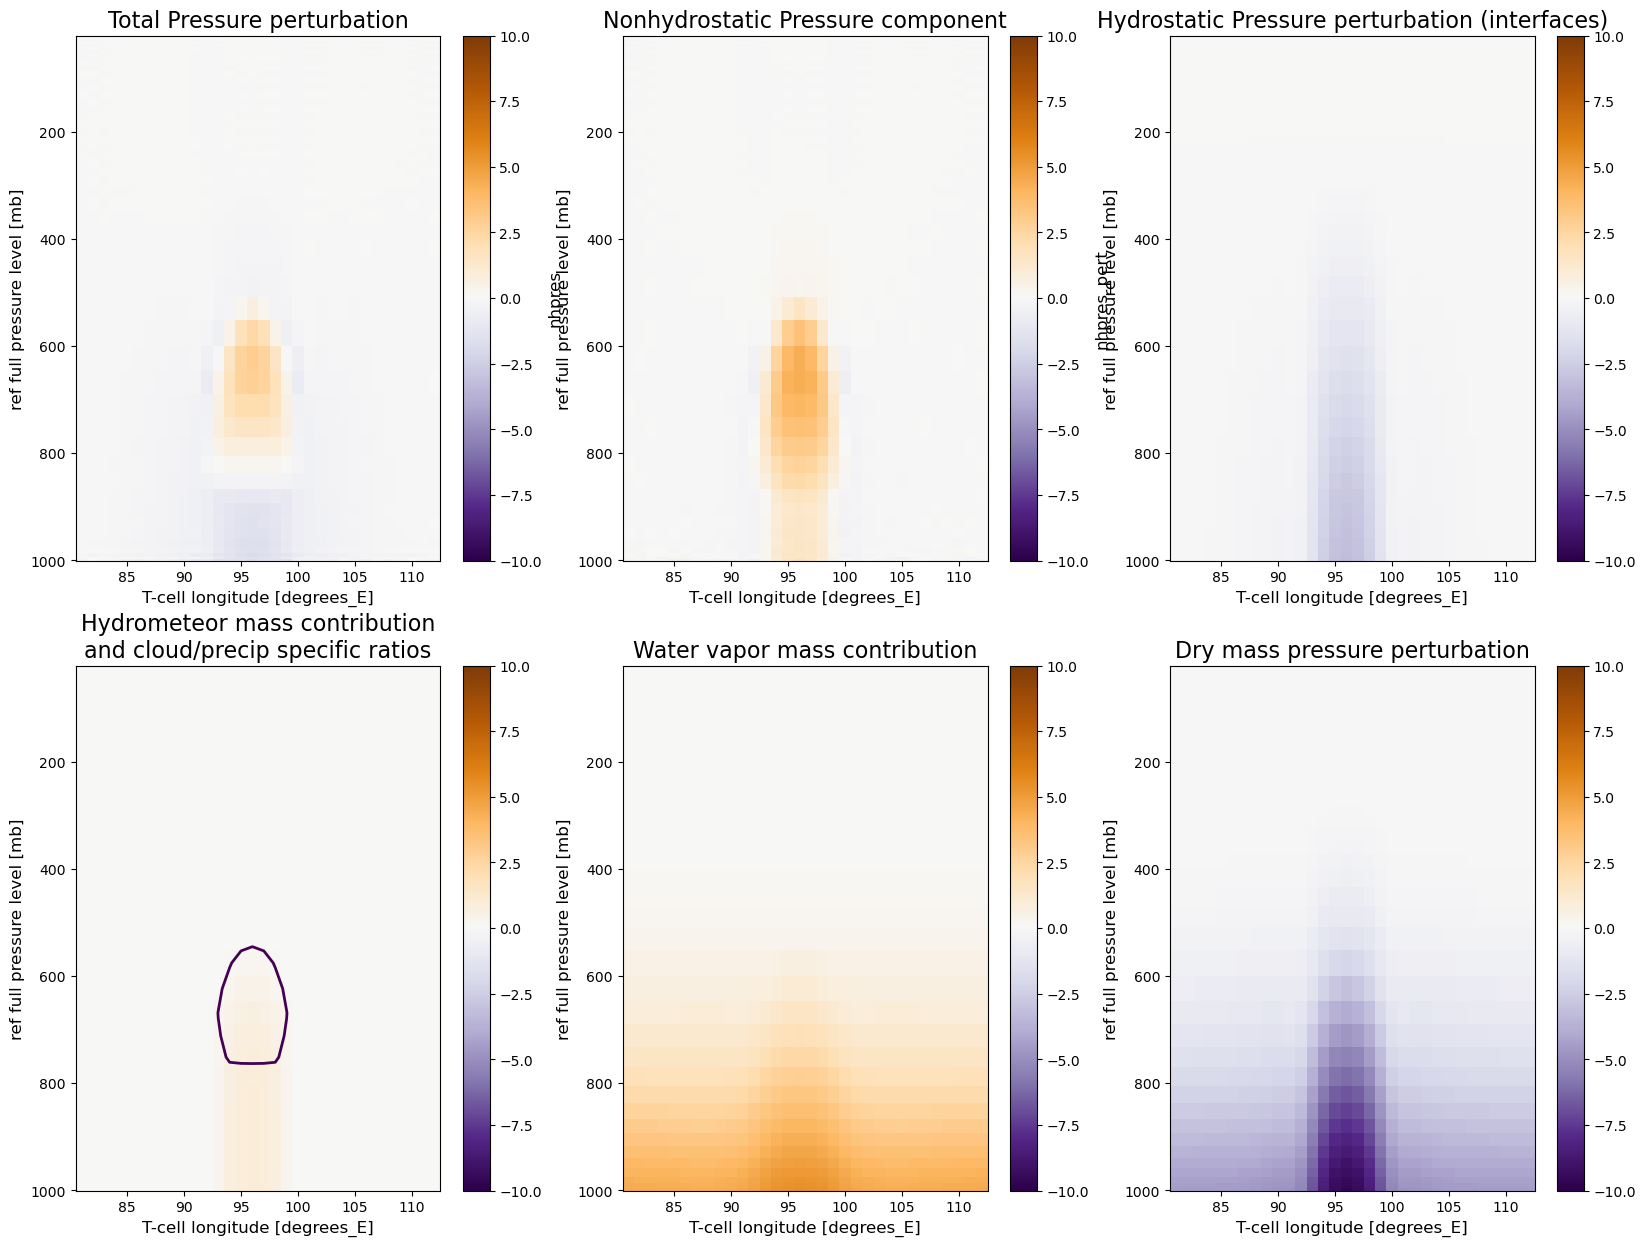

In [128]:
fig = plt.figure(figsize=(20,15))

#nhpres anom
ax = fig.add_subplot(2,3,1)
((ds_cross.nhpres-ds_ref.nhpres)/100).plot(ax=ax,yincrease=False,vmax=10,vmin=-10,cmap=plt.get_cmap('PuOr_r'))
ax.set_title("Total Pressure perturbation")

#nhpres_pert
ax = fig.add_subplot(2,3,2)
((ds_cross.nhpres_pert)/100.).plot(ax=ax,yincrease=False,vmax=10,vmin=-10,cmap=plt.get_cmap('PuOr_r'))
ax.set_title("Nonhydrostatic Pressure component")

ax = fig.add_subplot(2,3,3)
#phyd=(ds_cross.nhpres-ds_ref.nhpres-ds_cross.nhpres_pert)
((xphyd-xphyd_ref)/100.).plot(ax=ax,yincrease=False,vmax=10,vmin=-10,cmap=plt.get_cmap('PuOr_r'))
ax.set_title("Hydrostatic Pressure perturbation (interfaces)")

#hydrometeors
ax = fig.add_subplot(2,3,4)
qq=np.cumsum(ds_cross.qp + ds_cross.qn,axis=0)
cloud=ds_cross.qn/ds_cross.delp*1000. #g/kg 
prec=ds_cross.qp/ds_cross.delp*1000.

(xpcond/100.).plot(ax=ax,yincrease=False,vmax=10,vmin=-10,cmap=plt.get_cmap('PuOr_r'))
vvc=cloud.plot.contour(ax=ax,yincrease=False,color='k',levels=np.arange(2,10,2),linewidths=2)
vvp=prec.plot.contour(ax=ax,yincrease=False,color='darkgreen',levels=np.arange(2,15,2),linewidths=2)
ax.set_title("Hydrometeor mass contribution\nand cloud/precip specific ratios")

ax = fig.add_subplot(2,3,5)
((xpsphum)/100.).plot(ax=ax,yincrease=False,vmax=10,vmin=-10,cmap=plt.get_cmap('PuOr_r'))
ax.set_title("Water vapor mass contribution");

#dry pressure perturbation
ax = fig.add_subplot(2,3,6)
((xphyd-xphyd_ref-xpcond-xpsphum)/100.).plot(ax=ax,yincrease=False,vmax=10,vmin=-10,cmap=plt.get_cmap('PuOr_r'))
ax.set_title("Dry mass pressure perturbation");

# #NOTE: apparently this behavior will change in a future version of Matplotlib
# #  so if it makes empty plots then just remove it.
# for n in range(6):
#     ax = fig.add_subplot(2,3,n+1)
#     ax.set_xlabel("")

In [123]:
ds.dims

FrozenMappingWarningOnValuesAccess({'grid_xt': 192, 'grid_yt': 192, 'time': 60, 'pfull': 50, 'phalf': 51})